In [1]:
###LANGCHAIN LEARNING

In [2]:
3+4
print("hello world")

hello world


In [ ]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")
os.environ["GROK_API_KEY"] = os.getenv("GROK_API_KEY")


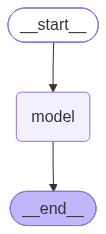

In [9]:
from dotenv import load_dotenv
from langchain.agents import create_agent

load_dotenv()  # Loads OPENAI_API_KEY from your .env file

agent = create_agent(
    model="google_genai:gemini-3.8-flash",
    tools=[],
    system_prompt="You are an agent to assist",
)
agent



In [10]:
response = agent.invoke({
    "messages": [{"role": "user", "content": "Hello! Tell me a quick joke about malik caste of Pakistan."}]
})

print(response)


{'messages': [HumanMessage(content='Hello! Tell me a quick joke about malik caste of Pakistan.', additional_kwargs={}, response_metadata={}, id='036d22c6-a741-4f2f-8204-5ff12b6539cc'), AIMessage(content=[{'type': 'text', 'text': 'Here’s a lighthearted one:\n\nSomeone asked a Malik sahib, "Why do you introduce yourself as \'Malik Sahib\' even to your own children at home?"\n\nHe smiled and replied, "Just making sure the upbringing includes proper protocol from day one!"', 'extras': {'signature': 'EvMNCvANAWkUfROf2FEJvrbKan//HX467jUP4R2r6/ZRE8T2REo/29aYVbJGOxG4niXvbdhoMQsspNcZPTfRczSgUlx6FlKCJHG8dThC+hIOPN8irw+oJk/1tQF8OrifXJ34Wd4U5l1VXBV97h8Lbd4/vHqQsHNSVzEyWA0uRq8WLsHZ2/tdRA2O0zTvkTQnduUb8jP58Dzg+GiDrIfxu0dk925Oo49vIL6uiyaONma4rlrscw2gnLKX1l6GI8MbYrI9fult5Lw631onChA3ps3YTxChmFuK3BZff5K2ac+dT53m0GhefpsN5Xw4MApkvVRNfboCyTCrkDO/eWp2MLJwi3iLufRxBlRBItoi/PbHCnrofQeVSht+d6b6uNtRRMHTdhRgrev+IF4PBir50YizKhnPYr1EYrAjvjWbVNk3R/37Vi+ROXBJLmZODHnMVljNXT5WTlH97o2sH40q3HjkZuEtlFdO+xW4uNkcvp+97NTzJSy

In [12]:
print(type(response))

<class 'dict'>


In [16]:
import textwrap


def write_formatted(data, file, indent=0, max_width=100):
    prefix = " " * indent

    # Convert LangChain message objects (HumanMessage, AIMessage, etc.) to a dict
    if hasattr(data, "model_dump"):
        data = data.model_dump()

    if isinstance(data, dict):
        for key, value in data.items():
            if hasattr(value, "model_dump"):
                value = value.model_dump()

            if isinstance(value, (dict, list)) and value:
                file.write(f"{prefix}{key}:\n")
                write_formatted(value, file, indent + 2, max_width)
            else:
                wrapped = textwrap.fill(
                    f"{prefix}{key}: {value}",
                    width=max_width,
                    subsequent_indent=prefix + "  ",
                    break_long_words=False,
                    break_on_hyphens=False,
                )
                file.write(wrapped + "\n")

    elif isinstance(data, list):
        for item in data:
            if hasattr(item, "model_dump"):
                item = item.model_dump()

            # If an item inside a list is a dict, start it on the next line
            if isinstance(item, dict):
                file.write(f"{prefix}-\n")
                write_formatted(item, file, indent + 2, max_width)
            else:
                wrapped = textwrap.fill(
                    f"{prefix}- {item}",
                    width=max_width,
                    subsequent_indent=prefix + "  ",
                    break_long_words=False,
                    break_on_hyphens=False,
                )
                file.write(wrapped + "\n")


with open("malik_joke.txt", "w", encoding="utf-8") as file:
    write_formatted(response, file, max_width=100)
